# GJ 3929 b with MIRI/F1500W: joint fit of several eclipses

GJ 3929 b is a rocky planet (1.1 Earth radii) on a 2.6-day orbit around an M
dwarf. Whether such planets keep an atmosphere is the question of the
*Rocky Worlds* DDT programme (9235), which observed four eclipses of
GJ 3929 b with MIRI imaging at 15 µm. A bare rock that re-radiates its
heat where it is absorbed has the hottest dayside and the deepest eclipse;
an atmosphere that carries heat to the nightside makes it shallower. Xue et al. (2025, arXiv:2508.12516)
analysed the first two eclipses and Connors et al. (2026, arXiv:2606.07511)
all four.

At ~120 ppm the eclipse is only about 4σ per visit, so this tutorial is
about precision photometry and about fitting weak signals:

* MIRI imaging photometry: aperture and PSF-weighted fluxes;
* a joint fit of five datasets (four visits, one split into two
  exposures), each with its own systematics;
* how to treat the eclipse time of a weak eclipse: free, or with a prior
  from an independent measurement (and why it must never be *fixed* in
  juliet).

**Contents**

1. The data
2. Stage 1 and cleaning (one segment)
3. Photometry (one segment)
4. The five light curves
5. Joint eclipse fits
6. Summary

## 1. The data

| | |
| --- | --- |
| Programme | JWST DDT 9235 (Rocky Worlds), observations 1-5 (2025) |
| Mode | MIRI imaging, F1500W, SUB128, FASTR1 |
| Integrations | ~3000-3400 per visit, 47 groups (5.7 s per integration) |
| Datasets | V1, V2, V3, V4a (observation 4) and V4b (observation 5, starting 16 min after V4a ended: the continuation of visit 4) |

Each visit lasts about 5 hours. Visit 4 was split into two observations;
they are kept as two datasets (`V4a`, `V4b`) because each starts with its
own settling ramp.

```python
from astroquery.mast import Observations

obs = Observations.query_criteria(obs_collection='JWST', proposal_id='9235',
                                  instrument_name='MIRI/IMAGE')
prods = Observations.filter_products(Observations.get_product_list(obs),
                                     productSubGroupDescription='UNCAL')
roots = ('jw09235001001_03101', 'jw09235002001_03101', 'jw09235003001_03101',
         'jw09235004001_03101', 'jw09235005001_02101')
keep = [f.startswith(roots) for f in prods['productFilename']]
Observations.download_products(prods[keep], download_dir=DATA, flat=True)   # then sort into V1 ... V4
```

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from jstark.reduction import Stage1, ExposureCleaner
from jstark.reduction import diagnostics as rdiag
from jstark.extraction import Photometry
from jstark.extraction import diagnostics as xdiag
from jstark.extraction.metrics import p2p_sigma
from jstark.fitting import LightCurves, BroadbandFit

BASE = '/Volumes/Jayshil SSD/JWST/gj3929/Data'
DATA = os.path.join(BASE, 'uncal')                  # V1, V2, V3, V4 folders with the uncal files
TUT = os.path.join(BASE, 'tutorial')                # segment 1 of visit 1 (this notebook)
FITS = os.path.join(BASE, 'fits')
EXPOSURES = {'V1': ('V1', 'jw09235001001_03101'), 'V2': ('V2', 'jw09235002001_03101'),
             'V3': ('V3', 'jw09235003001_03101'), 'V4a': ('V4', 'jw09235004001_03101'),
             'V4b': ('V4', 'jw09235005001_02101')}
PHOT = {k: os.path.join(DATA, d, 'reduction_current', f'{root}_00001_mirimage_photometry.fits')
        for k, (d, root) in EXPOSURES.items()}
RUN_FULL = False

from jstark.plotting import use_style
use_style()                                         # the style of the jstark diagnostic plots
%config InlineBackend.figure_formats = ['retina']
os.makedirs(TUT, exist_ok=True)

## 2. Stage 1 and cleaning (one segment)

The MIRI recipe is the same as for LRS (see the
[WASP-43 b tutorial](wasp43b_miri_lrs.ipynb)): the official time-series
configuration plus `consistent_saturation` and `temporal_jump`.

In [2]:
s1 = Stage1(os.path.join(DATA, 'V1'), outdir=TUT)
s1.set('ramp_fit', maximum_cores='4')
s1.show()

jstark Stage1: MIRI/F1500W | exposure jw09235001001_03101_00001_mirimage | 5 segment(s) | output -> /Volumes/Jayshil SSD/JWST/gj3929/Data/tutorial
Recipe for MIRI/F1500W:
   0. [run ] jwst   group_scale          
   1. [run ] jwst   dq_init              
   2. [run ] jwst   emicorr              
   3. [run ] jwst   saturation           
   4. [run ] jstark consistent_saturation {'min_frac': 0.01, 'scope': 'exposure'}
   5. [SKIP] jwst   firstframe           {'bright_use_group1': True}
   6. [run ] jwst   lastframe            
   7. [run ] jwst   reset                
   8. [run ] jwst   linearity            
   9. [SKIP] jwst   rscd                 
  10. [run ] jwst   dark_current         
  11. [SKIP] jwst   refpix               
  12. [SKIP] jstark group_bkg            {'method': 'median', 'axis': 'row'}
  13. [SKIP] jwst   jump                 {'rejection_threshold': 15.0, 'maximum_cores': 'half'}
  14. [run ] jstark temporal_jump        {'window': 11, 'threshold': 10.0, 'mode': 'a

  saturation pre-pass: segment 1/5
  saturation map: 0 pixels saturate (in >= 1% of integrations); first saturated group histogram [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 17408]
Segment 1/5: jw09235001001_03101_00001-seg001_mirimage_uncal.fits


    group_scale          done in    0.4 s


    dq_init              done in    0.5 s


    emicorr              done in   46.5 s


    saturation           done in    4.2 s


    consistent_saturation: 0 pixels, 0 saturated-group flags added
    consistent_saturation done in    0.7 s


... (3 outputs left out)

    dark_current         done in    0.9 s


    temporal_jump: 4129 jumps (flag), median fraction of pixels hit per integration = 0.017%
    temporal_jump        done in   63.3 s


    ramp_fit             done in   16.8 s
    gain_scale           done in    0.1 s


  -> /Volumes/Jayshil SSD/JWST/gj3929/Data/tutorial/jw09235001001_03101_00001-seg001_mirimage_rateints.fits  (137.4 s)
CPU times: user 2min 39s, sys: 16 s, total: 2min 55s
Wall time: 3min 17s


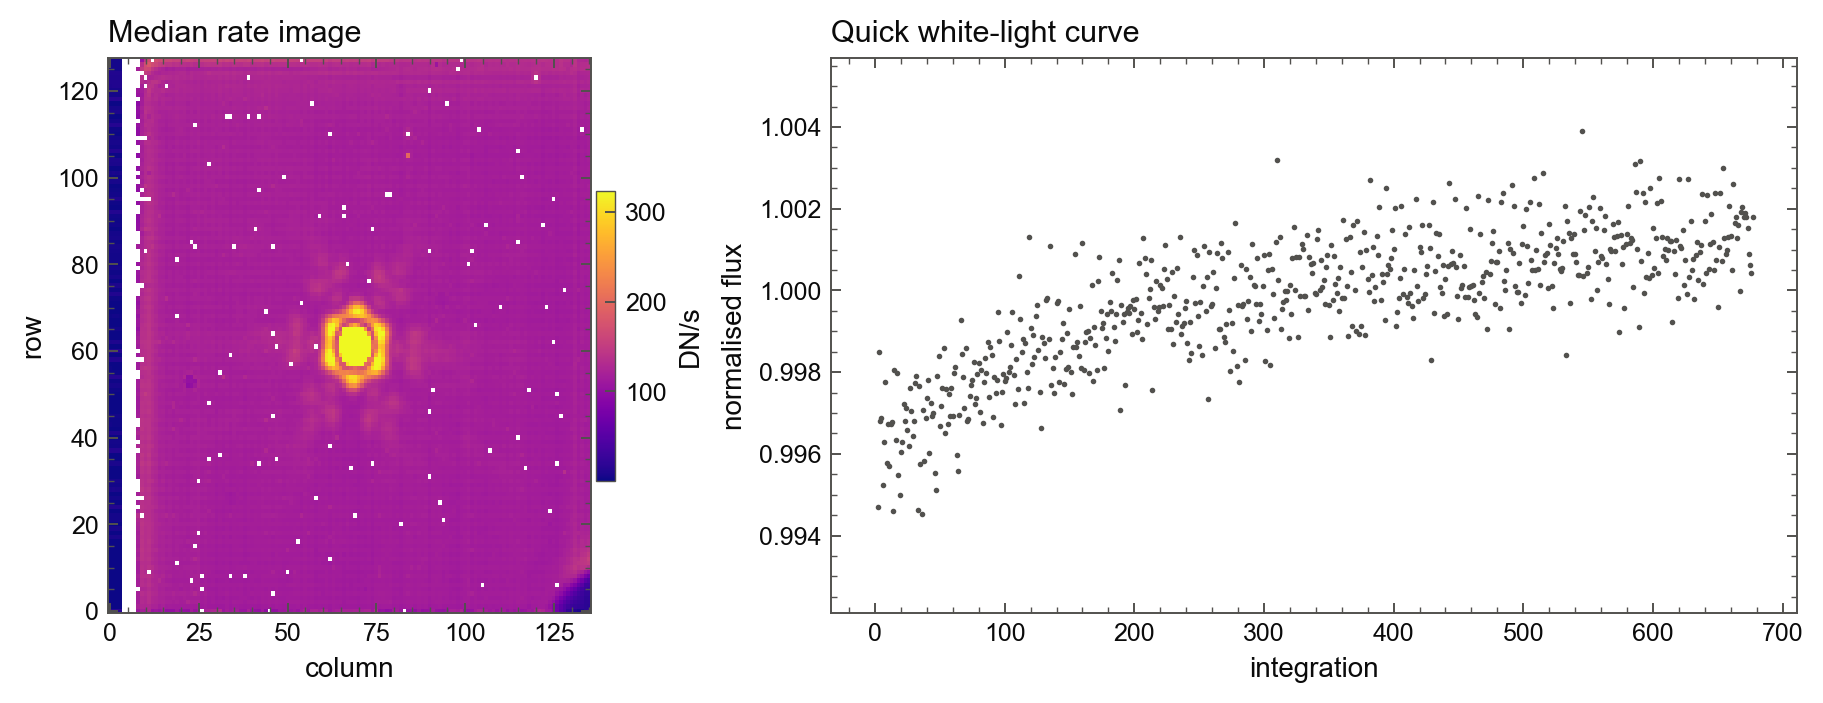

In [3]:
%%time
s1.compute_saturation_map(segments=[0])
rateints = s1.run(segments=[0])
rdiag.plot_rateints(rateints[0]);

<div class="alert alert-info">

**Why the whole ramp is fitted**

MIRI ramps rise too steeply in their first groups (see the WASP-43 b
tutorial). On these data (development tests, with the Stage 1 settings
used before November 2026), aperture photometry (4 px, sky 15-25 px, after
the first 60 integrations) was compared for different first groups of the
ramp fit:

| First group | Scatter (ppm) | Median error (ppm) | First 10 integrations vs late | Red-noise factor |
| --- | --- | --- | --- | --- |
| 0 | 740 | 627 | −0.95% | 4.07 |
| 4 | 802 | 643 | −0.97% | 4.02 |
| 8 | 847 | 677 | −0.97% | 3.89 |
| 12 | 944 | 717 | −0.97% | 3.77 |

The distortion of the early groups is the same in every integration, so it
only rescales the flux (by ~0.3%), and the drift at the start of the visit
is the detector settling, not the ramp start. Dropping groups only costs
precision. The default fits all usable groups.

</div>

In [4]:
%%time
info = ExposureCleaner(TUT).run()
cc = ExposureCleaner.load(info).load_segment(0)
cc.summary()

ExposureCleaner: MIRI/F1500W | jw09235001001_03101_00001_mirimage | 1 segment(s), 678 integrations


  pass 1: segment 1/1 read
compute_global: 1184 bad pixels from DQ, 16 hot/noisy pixels; trace mask 37.9% of pixels


  segment 1/1: 1517 transient flags (2.2 per integration) -> jw09235001001_03101_00001-seg001_mirimage_cleaned.fits
Saved exposure info to /Volumes/Jayshil SSD/JWST/gj3929/Data/tutorial/jw09235001001_03101_00001_mirimage_cleaninfo.fits
MIRI/F1500W: (678, 128, 136); persistent bad pixels: 1200 (6.89%); transient flags: 1517 (0.0129%, 2.2 per integration)
CPU times: user 4.46 s, sys: 257 ms, total: 4.72 s
Wall time: 4.93 s


'MIRI/F1500W: (678, 128, 136); persistent bad pixels: 1200 (6.89%); transient flags: 1517 (0.0129%, 2.2 per integration)'

## 3. Photometry (one segment)

`Photometry` measures, for every integration:

* the sky, as the 3σ-clipped median of an annulus (15-25 px);
* the centroid, from the centre of flux refined by a PSF fit;
* **aperture photometry** with exact pixel overlaps (radius 4 px);
* **PSF-weighted photometry**: an optimal estimate with an empirical PSF
  (the time-averaged normalised image, shifted to each centroid with a
  bicubic spline), within 8 px.

In [5]:
ph = Photometry(info)
ph.show()
ph.fit_psf();

Photometry: MIRI/F1500W | jw09235001001_03101_00001_mirimage | 1 segment(s), 678 integrations
  centroid   halfwidth=6.0, niter=3
  background method=annulus, r_in=15.0, r_out=25.0, nsigma=3.0
  aperture   radius=4.0
  psf        halfwidth=12.0, ints=all
  extract    psf_radius=8.0, fit_background=False, variance=mean, pld_radius=None, refine_center=2
  star at (row, col) = (61.24, 69.08)


  empirical PSF from 678 integrations (0 s)


In [6]:
%%time
opt = ph.optimise(radii=[3, 4, 5, 6], psf_radii=[6, 8, 10], apply=False)

  aperture radius : 3: 808 ppm (1.23), 4: 778 ppm (1.28), 5: 788 ppm (1.31), 6: 828 ppm (1.36)
  PSF radius      : 6: 774 ppm (1.21), 8: 761 ppm (1.23), 10: 753 ppm (1.23)
CPU times: user 2.77 s, sys: 356 ms, total: 3.13 s
Wall time: 3.16 s


<div class="alert alert-info">

**Why PSF weighting**

At 15 µm the background (telescope and zodiacal light) is bright, and the
star's light is spread over a wide PSF. Aperture photometry must choose
between losing starlight (small aperture) and adding background noise
(large aperture). PSF weighting uses every pixel with a weight that
follows its signal-to-noise. On these data (development tests with the
earlier Stage 1 settings, 3 × 300 integrations; ppm, and in brackets the
ratio to the propagated error):

| Radius (px) | Aperture | PSF-weighted |
| --- | --- | --- |
| 3 | 783 (1.17) | |
| 4 | 779 (1.26) | |
| 5 | 799 (1.30) | 754 (1.17) |
| 6 | 789 (1.28) | 769 (1.20) |
| 8 | 793 (1.29) | **737 (1.18)** |
| 10 | | 769 (1.25) |

PSF weighting gains about 4%. On the full light curves it also has less red
noise (β at 128 integrations 1.19 against 1.63 for the aperture).

</div>

  segment 1/1: 678 integrations
Saved photometry to /Volumes/Jayshil SSD/JWST/gj3929/Data/tutorial/jw09235001001_03101_00001_mirimage_photometry.fits
aperture  p2p   772 ppm, ratio to errors 1.27
psf       p2p   738 ppm, ratio to errors 1.19
CPU times: user 342 ms, sys: 46.1 ms, total: 388 ms
Wall time: 457 ms


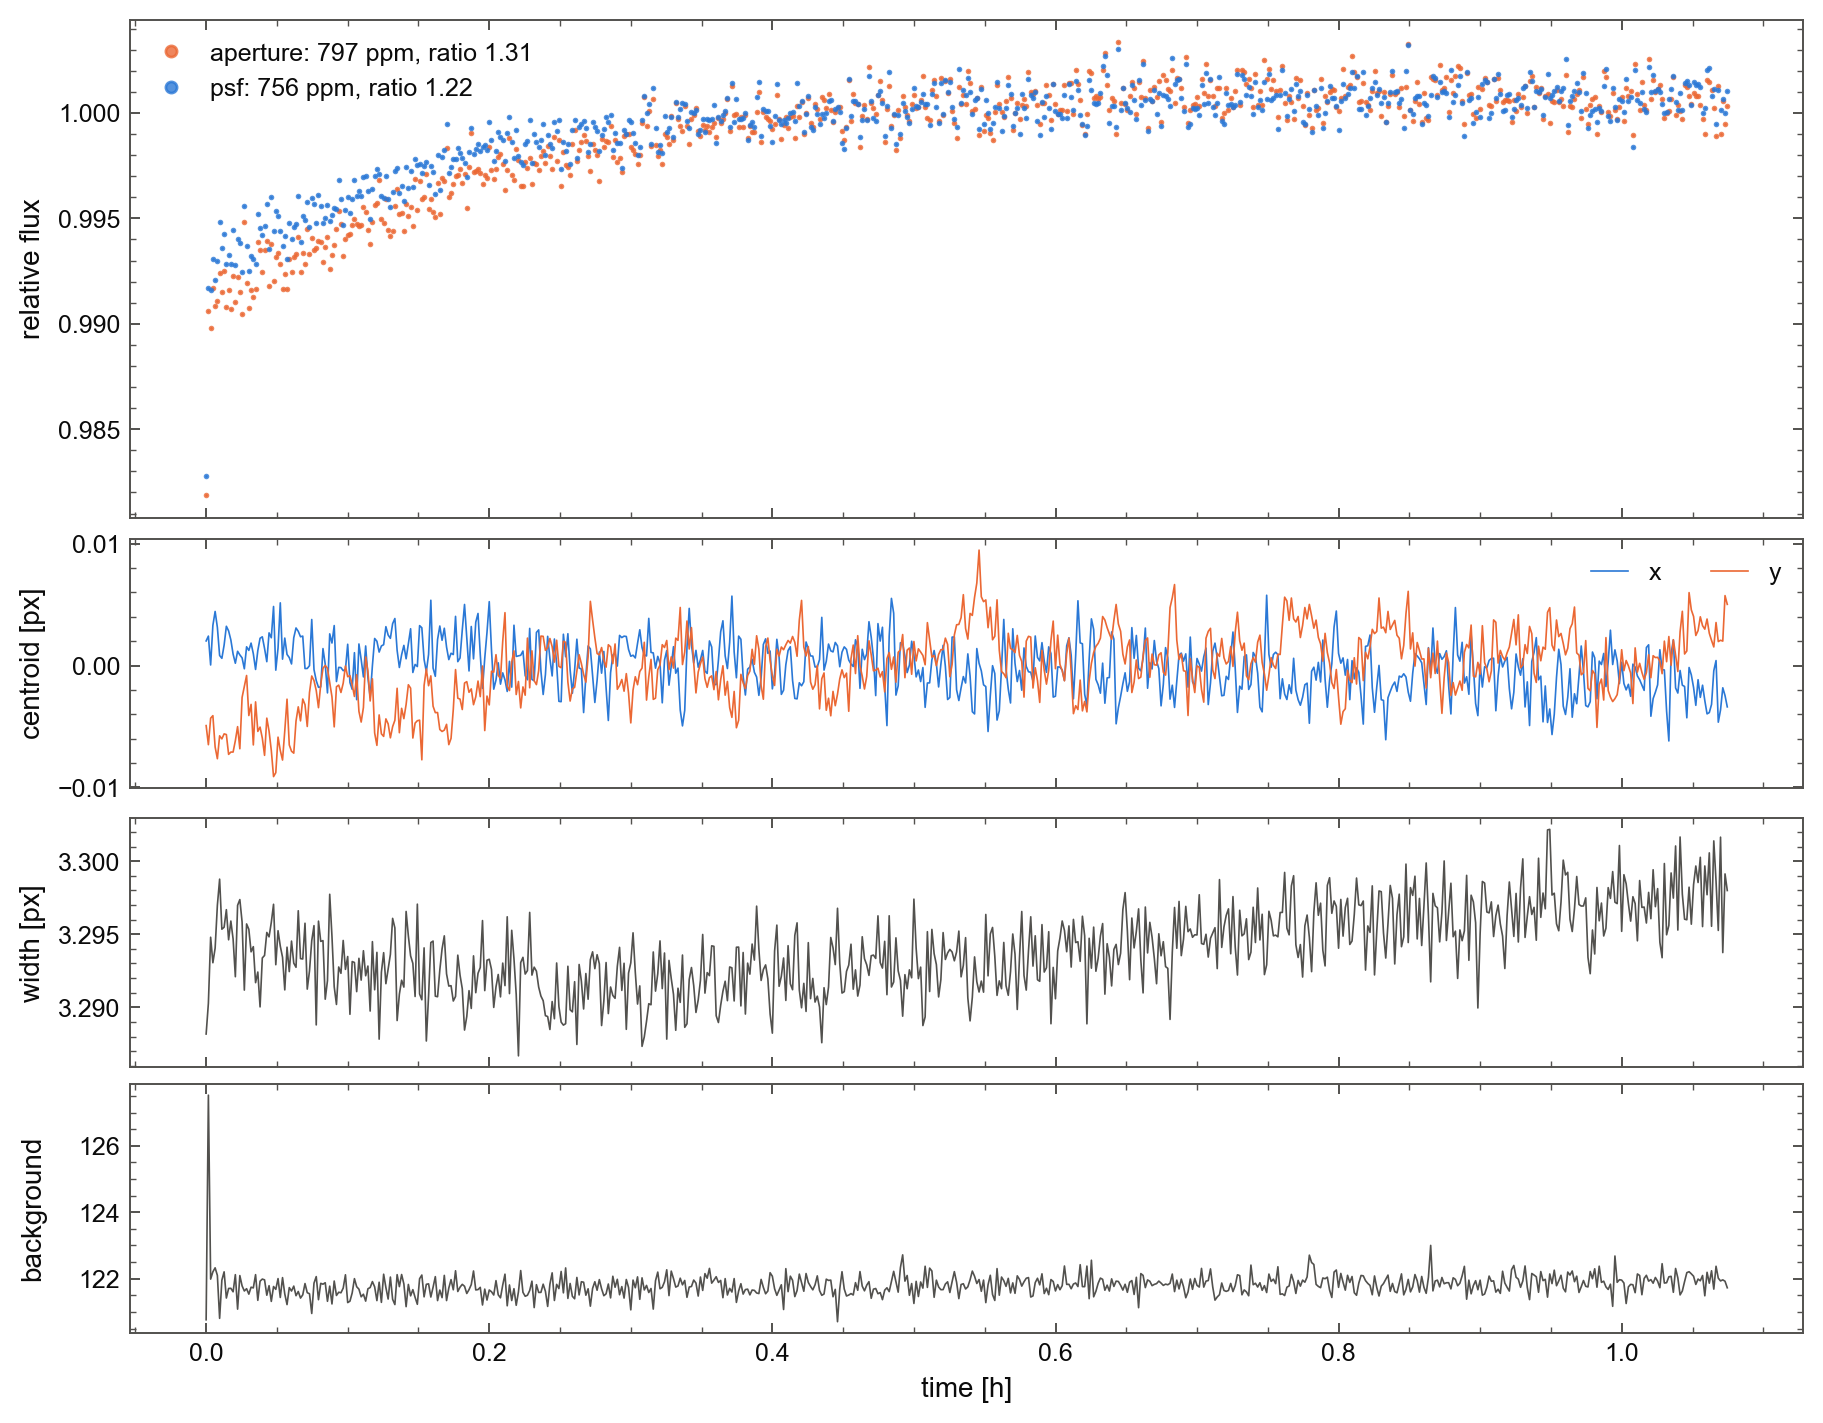

In [7]:
%%time
res1 = ph.run()
xdiag.plot_photometry(res1);
for k in ('aperture', 'psf'):
    f = res1.flux[k] / np.nanmedian(res1.flux[k])
    e = res1.err[k] / np.nanmedian(res1.flux[k])
    print(f'{k:9s} p2p {p2p_sigma(f[60:]) * 1e6:5.0f} ppm, ratio to errors {p2p_sigma(f[60:]) / np.median(e):.2f}')

## 4. The five light curves

All five exposures were reduced with the same code (Stage 1 takes 8-18
minutes per exposure here, one exposure at a time; cleaning and photometry under a minute).
`LightCurves.from_photometry` reads the PSF-weighted light curve with the
regressors `xc`, `yc` (centroid), `width` and `bkg`.

V1   3387 integrations, p2p 722 ppm
V2   3863 integrations, p2p 723 ppm
V3   3891 integrations, p2p 735 ppm
V4a  2980 integrations, p2p 745 ppm
V4b  1637 integrations, p2p 749 ppm


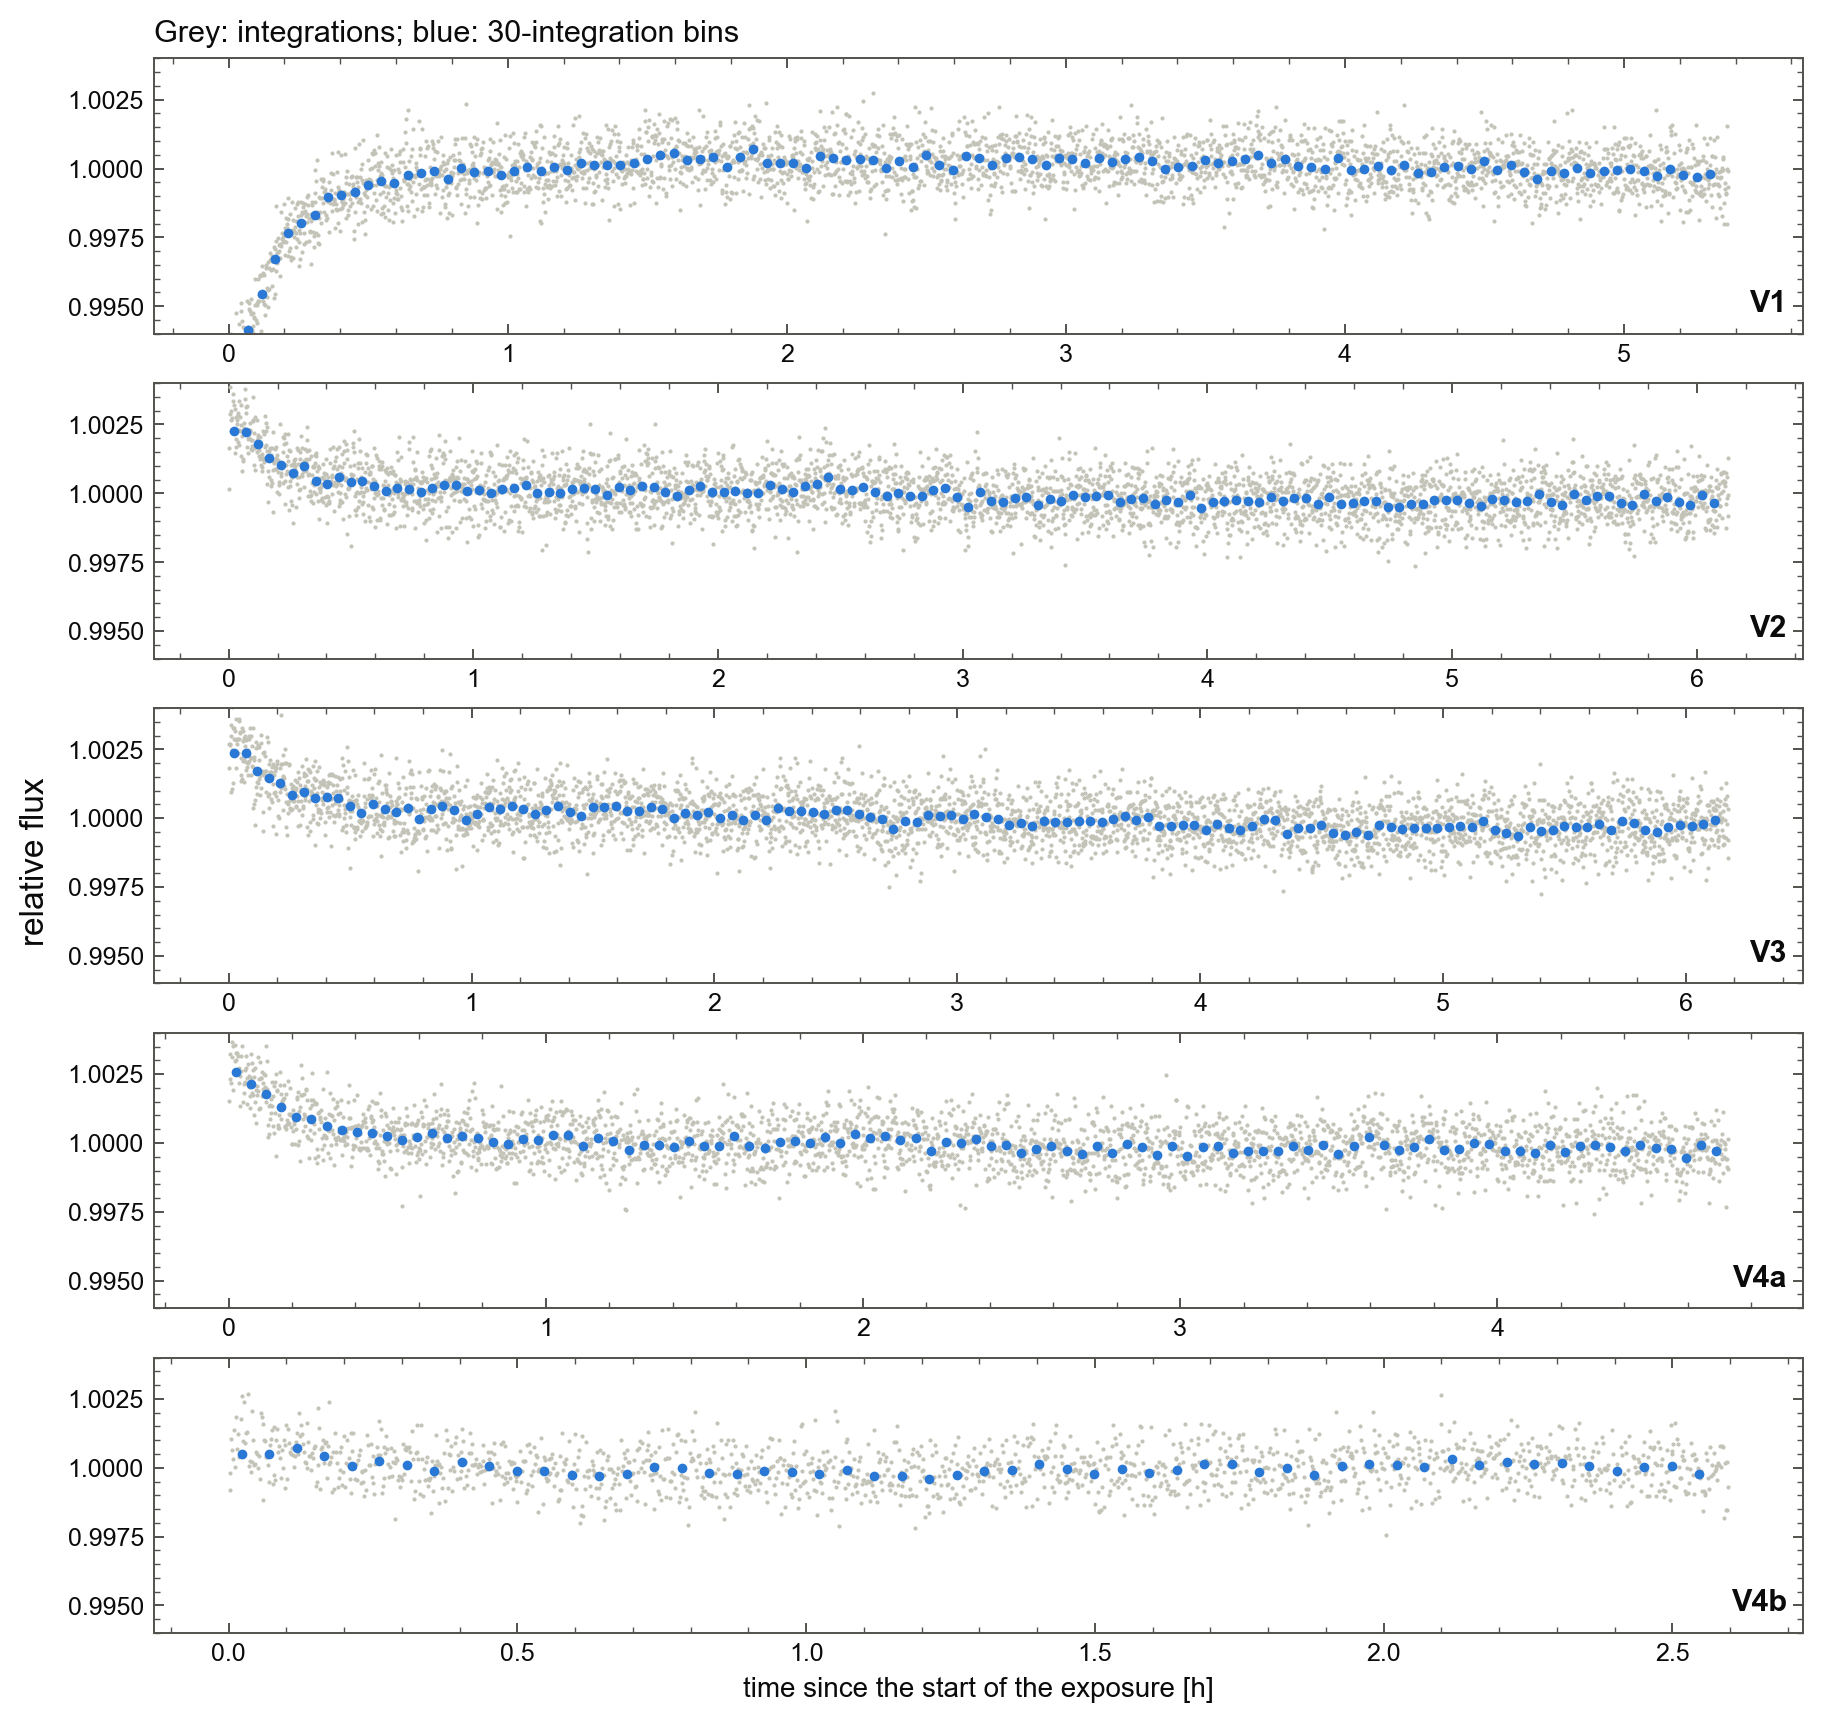

In [8]:
if RUN_FULL:
    for name, (d, root) in EXPOSURES.items():
        out = os.path.join(DATA, d, 'reduction_current')
        s1 = Stage1(os.path.join(DATA, d), outdir=out, exposure=root)
        s1.set('ramp_fit', maximum_cores='4')
        s1.run(save_variances=False)
        Photometry(ExposureCleaner(out, exposure=root).run()).run()

lcs = {k: LightCurves.from_photometry(f, method='psf', name=k) for k, f in PHOT.items()}
fig, axs = plt.subplots(len(lcs), 1, figsize=(9, 8.5), sharey=True, layout='constrained')
for ax, (k, lc) in zip(axs, lcs.items()):
    f, e = lc.white_light()
    t = (lc.times - lc.times[0]) * 24
    nb = 30
    n = len(f) // nb
    ax.plot(t, f, '.', color='#c3c2b7', ms=1)
    ax.plot(t[:n * nb].reshape(n, nb).mean(1), f[:n * nb].reshape(n, nb).mean(1), 'o', color='C0', ms=2.5)
    ax.text(0.99, 0.08, k, transform=ax.transAxes, ha='right', fontsize=11, weight='bold')
    print(f'{k:4s} {len(f)} integrations, p2p {p2p_sigma(f[500:]) * 1e6:.0f} ppm')
axs[0].set_ylim(0.994, 1.004)
axs[-1].set_xlabel('time since the start of the exposure [h]')
fig.supylabel('relative flux')
axs[0].set_title('Grey: integrations; blue: 30-integration bins');

Every visit starts with a ramp: the flux settles by about 1% over the
first hour, with the opposite sign in V1. The eclipse (~120 ppm, 1.3 h) is
invisible in a single visit.

## 5. Joint eclipse fits

All five datasets are fitted together: one eclipse depth `fp` and one
eclipse time for all, and per dataset a flux offset, a jitter term, an
exponential ramp, and a linear model in time and centroid position
(`xc`, `yc`). The orbit is fixed except $a/R_*$ and $b$ (priors from the
transits), $R_p/R_*$ is fixed; there are no limb-darkening priors, so juliet
fits an eclipse only (jstark warns about this, which is intended here).

The trimming follows Connors et al.: the first 500 integrations of each
dataset, and 1500 of V4a, which shows a suspected tilt event.

In [9]:
P, T0 = 2.6162644, 2460452.8997                     # Xue et al. (2025)
T_HALF = T0 + 157.5 * P                             # phase 0.5 just before visit 1
trim = {'V1': 500, 'V2': 500, 'V3': 500, 'V4a': 1500, 'V4b': 500}
lcs_fit = {k: lc.exclude(ints=[(0, trim[k])]) for k, lc in lcs.items()}
geometry = {'P_p1': ('fixed', P), 't0_p1': ('fixed', T0),
            'p_p1': ('fixed', 0.0318), 'a_p1': ('normal', [17.04, 0.5]),
            'b_p1': ('truncatednormal', [0.21, 0.12, 0., 1.]),
            'ecc_p1': ('fixed', 0.), 'omega_p1': ('fixed', 90.),
            'fp_p1': ('uniform', [-1e-3, 1e-3])}

### 5.1 Eclipse time free

A small eccentricity shifts the eclipse away from phase 0.5. The obvious
choice is to fit its time, with one `t_secondary` for all visits within
±0.05 days (±72 min) of phase 0.5.

Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/gj3929/Data/fits/current_eclipses_D/_dynesty_DNS_posteriors.pkl


fp = 134 +17 -19 ppm; eclipse time -8.5 min from phase 0.5; 0.0% of the samples within 15 min of -54 min


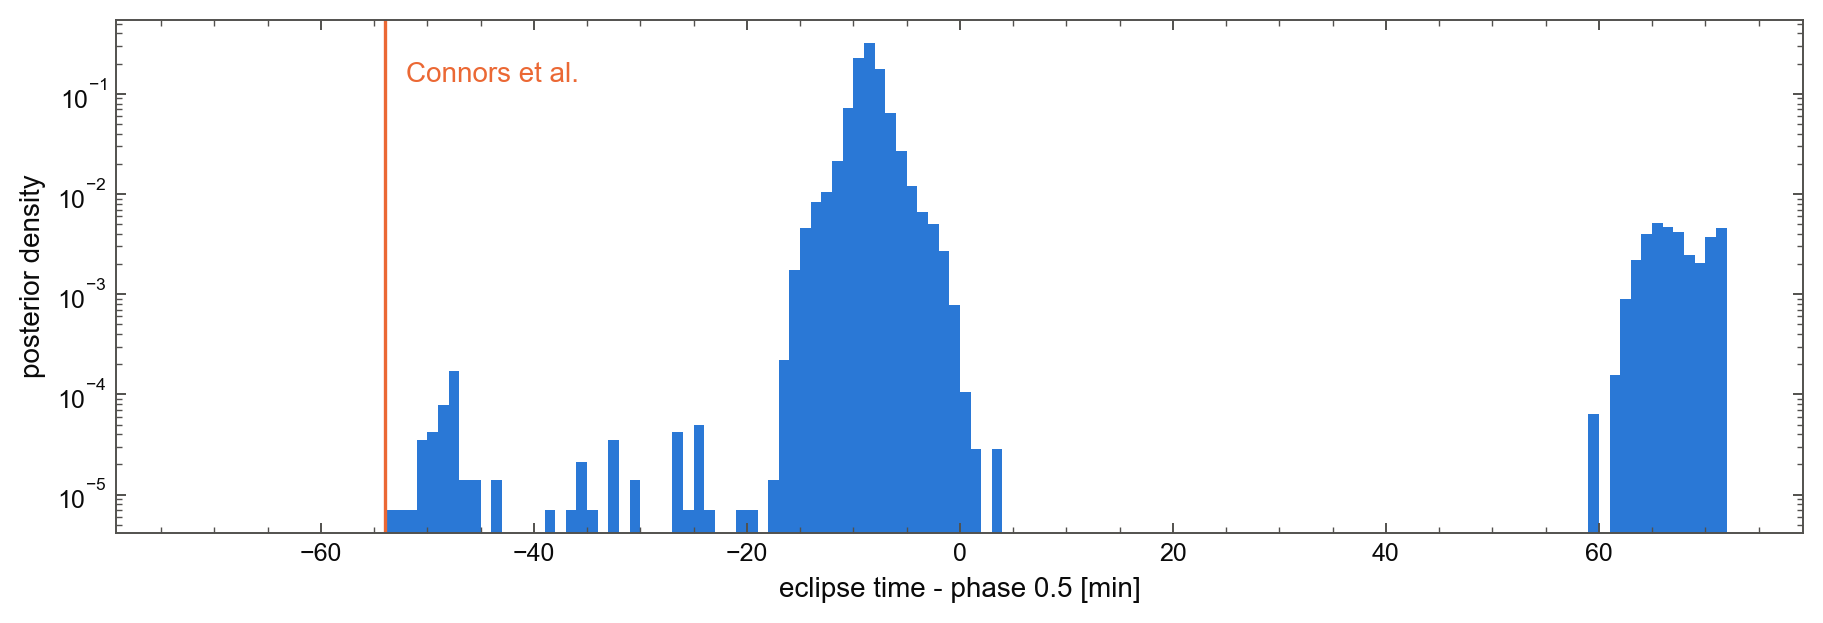

In [10]:
fit_free = os.path.join(FITS, 'current_eclipses_D')
if RUN_FULL:
    pri = dict(geometry, t_secondary_p1=('uniform', [T_HALF - 0.05, T_HALF + 0.05]))
    BroadbandFit(lcs_fit, priors=pri, out_folder=fit_free,
                 linear=['time', 'xc', 'yc'], ramp=1).fit(nthreads=8)      # ~25 min
fD = BroadbandFit.load(fit_free)
post = fD.results.posteriors['posterior_samples']
dt = (post['t_secondary_p1'] - T_HALF) * 1440
fig, ax = plt.subplots(figsize=(9, 3), layout='constrained')
ax.hist(dt, bins=144, range=(-72, 72), color='C0', density=True)
ax.set_xlabel('eclipse time - phase 0.5 [min]'); ax.set_ylabel('posterior density')
ax.set_yscale('log')
for x, lab in ((-54, 'Connors et al.'),):
    ax.axvline(x, color='C1', lw=1.2); ax.text(x + 2, 0.88, lab, color='C1', transform=ax.get_xaxis_transform())
lo, md, hi = np.percentile(post['fp_p1'] * 1e6, [16, 50, 84])
print(f"fp = {md:.0f} +{hi - md:.0f} -{md - lo:.0f} ppm; eclipse time {np.median(dt):+.1f} min from phase 0.5; "
      f"{np.mean(np.abs(dt + 54) < 15) * 100:.1f}% of the samples within 15 min of -54 min")

<div class="alert alert-info">

**The eclipse time of a weak eclipse**

With the time free, the joint posterior is multimodal: 94% of it lies at
−8.5 ± 1.4 min, and ~3% at +60 to +72 min, against the edge of the prior. Connors et
al. (2026), with the same data but a different reduction and systematics
model, found the eclipse 54 ± 2 min before phase 0.5 (e cos ω = −0.0225).
Here the best likelihood near −54 min (from the fit in 5.2) is about 10
in ln L below the one at −8 min.

Such a preference should not be over-read. The residuals have red noise
(β at 128 integrations up to 1.6 for V3), which inflates likelihood
differences by roughly β², and each visit carries only ~4σ of eclipse.
Different reasonable systematics models can move the best time by tens of
minutes. What matters for the science case is the depth, and the
depth barely depends on the time: 134 ± 18 ppm here, 111 ± 18 ppm with the
time from Connors et al. (below).

On low signal-to-noise eclipses: fit with the time free *and* with a prior
from an independent constraint (radial velocities, a published joint fit),
check the `t_secondary` posterior for several modes, and report how much
the depth depends on the choice.

</div>

### 5.2 Eclipse time from an independent constraint

The time from Connors et al. enters as a narrow **normal prior**,
−54 ± 2 min from phase 0.5, with one depth for all visits (F) or one per
visit (E; V4a and V4b share one).

**Do not fix** `t_secondary` while the orbit is fitted (here $a/R_*$ and $b$).
With a fixed `t_secondary`, juliet and batman place the eclipse at the time
implied by `t0`, `ecc` and `omega`, i.e. at phase 0.5 for a circular orbit,
whatever value was given; a free `t_secondary`, even with a 2-min prior,
is handled correctly. jstark refuses the fixed case with an error.

In [11]:
fit_F, fit_E = os.path.join(FITS, 'current_eclipses_F'), os.path.join(FITS, 'current_eclipses_E')
if RUN_FULL:
    pri = dict(geometry, t_secondary_p1=('normal', [T_HALF - 54 / 1440, 2 / 1440]))
    BroadbandFit(lcs_fit, priors=pri, out_folder=fit_F,
                 linear=['time', 'xc', 'yc'], ramp=1).fit(nthreads=8)
    pri = {k: v for k, v in pri.items() if k != 'fp_p1'}
    for k in ('V1', 'V2', 'V3', 'V4a_V4b'):                # V4a and V4b share one depth
        pri[f'fp_p1_{k}'] = ('uniform', [-1e-3, 1e-3])
    BroadbandFit(lcs_fit, priors=pri, out_folder=fit_E,
                 linear=['time', 'xc', 'yc'], ramp=1).fit(nthreads=8)
fF, fE = BroadbandFit.load(fit_F), BroadbandFit.load(fit_E)

def fp_table(fit):
    s = fit.summary()
    return {r['name']: (r['median'] * 1e6, 0.5 * (r['err_plus'] + r['err_minus']) * 1e6)
            for r in s if r['name'].startswith('fp_p1') and not r['name'].endswith('ppm')}

for name, fit in (('D: time free', fD), ('F: time prior, one depth', fF), ('E: time prior, depth per visit', fE)):
    lnZ = fit.results.posteriors.get('lnZ', np.nan)
    dt = np.median(fit.results.posteriors['posterior_samples']['t_secondary_p1'] - T_HALF) * 1440
    txt = ', '.join(f"{k.replace('fp_p1', 'fp')} {v:.0f} +- {e:.0f}" for k, (v, e) in fp_table(fit).items())
    print(f'{name:31s} lnZ {lnZ:9.1f}  time {dt:+6.1f} min  {txt} ppm')

Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/gj3929/Data/fits/current_eclipses_F/_dynesty_DNS_posteriors.pkl


Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/gj3929/Data/fits/current_eclipses_E/_dynesty_DNS_posteriors.pkl


D: time free                    lnZ   70697.3  time   -8.5 min  fp 134 +- 18 ppm
F: time prior, one depth        lnZ   70693.8  time  -51.4 min  fp 111 +- 18 ppm


E: time prior, depth per visit  lnZ   70668.4  time  -53.6 min  fp_V1 65 +- 42, fp_V2 160 +- 27, fp_V3 77 +- 30, fp_V4a_V4b 89 +- 65 ppm


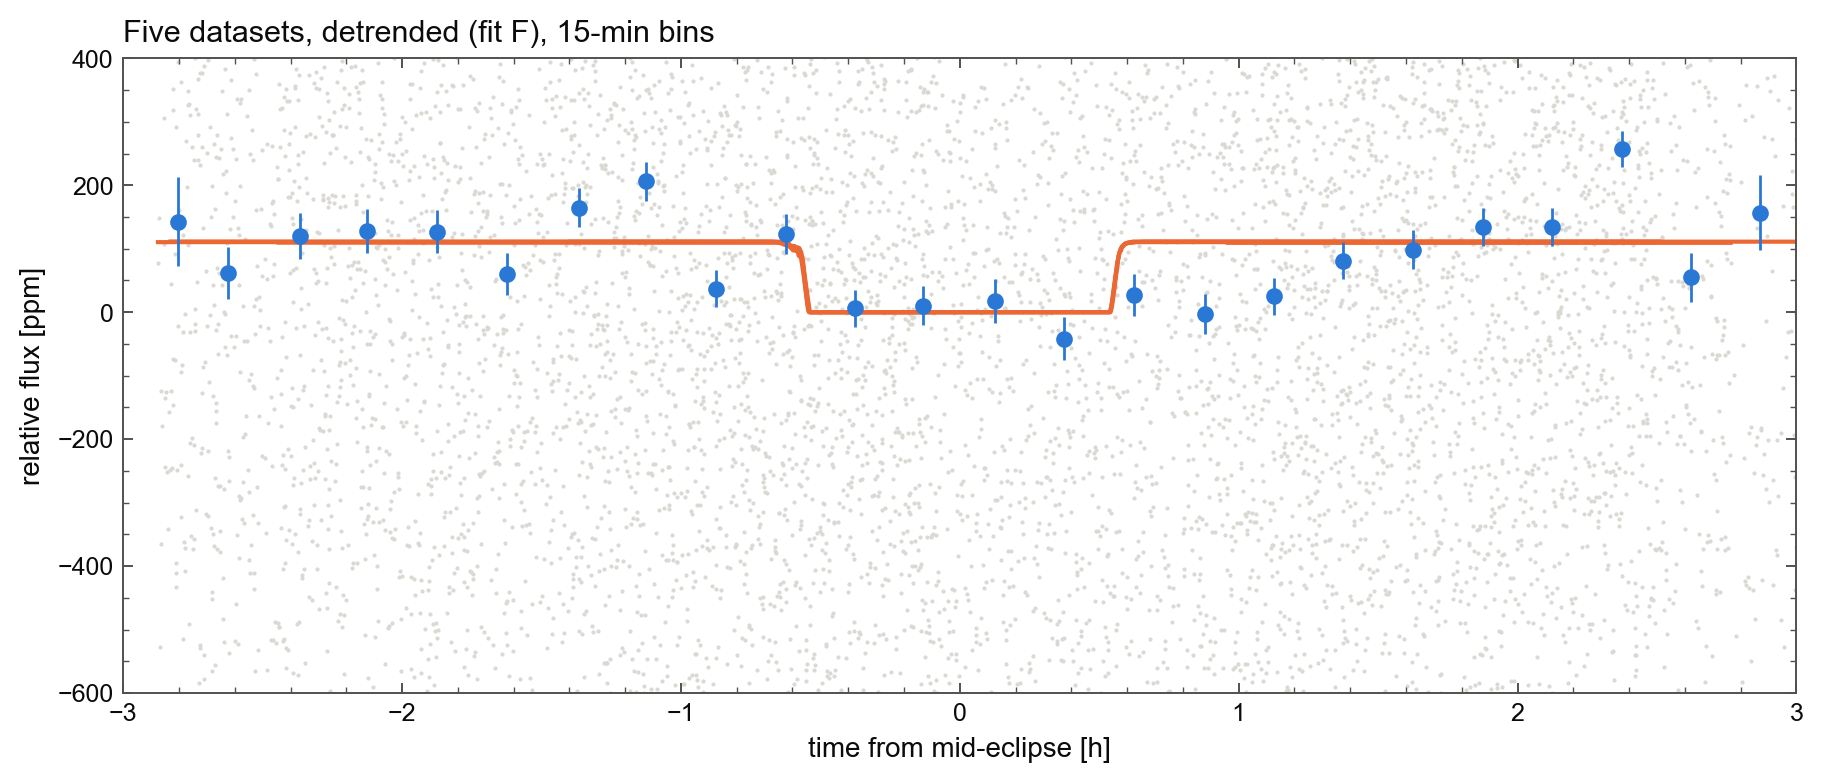

In [12]:
# all eclipses stacked: detrended data against the time from mid-eclipse
tsec = np.median(fF.results.posteriors['posterior_samples']['t_secondary_p1'])
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
x_all, y_all = [], []
for k in lcs_fit:
    r = fF.residuals(k, nsamples=200, components=True)
    x = ((r['t'] - tsec + P / 2) % P - P / 2) * 24
    ax.plot(x, (r['detrended'] - 1) * 1e6, '.', color='#d9d8d2', ms=1, zorder=0)
    x_all.append(x); y_all.append(r['detrended']); o = np.argsort(x)
    ax.plot(x[o], (r['planet'][o] - 1) * 1e6, '-', color='C1', lw=1.5)
x_all, y_all = np.concatenate(x_all), np.concatenate(y_all)
edges = np.arange(-3, 3.01, 0.25)
k = np.digitize(x_all, edges)
xb = np.array([x_all[k == i].mean() for i in range(1, len(edges)) if (k == i).sum() > 50])
yb = np.array([y_all[k == i].mean() for i in range(1, len(edges)) if (k == i).sum() > 50])
eb = np.array([y_all[k == i].std() / np.sqrt((k == i).sum()) for i in range(1, len(edges)) if (k == i).sum() > 50])
ax.errorbar(xb, (yb - 1) * 1e6, eb * 1e6, fmt='o', color='C0', ms=5, elinewidth=1, zorder=3)
ax.set_ylim(-600, 400); ax.set_xlim(-3, 3)
ax.set_xlabel('time from mid-eclipse [h]'); ax.set_ylabel('relative flux [ppm]')
ax.set_title('Five datasets, detrended (fit F), 15-min bins');

<div class="alert alert-info">

**What the fits show**

| Fit | Eclipse time (min from phase 0.5) | fp (ppm) | ln Z |
| --- | --- | --- | --- |
| D | free: −8.5 ± 1.4 (94% of the posterior) | 134 ± 18 | 70697.3 |
| **F** | **prior −54 ± 2 → −51.4 ± 1.5** | **111 ± 18** | **70693.8** |
| E | prior −54 ± 2, one depth per visit | V1 65 ± 42, V2 160 ± 27, V3 77 ± 30, V4 89 ± 65 | 70668.4 |
| Connors et al. (2026) | −54 ± 2 | 118 ± 22 (per visit 190, 155, 60, 97) | |
| Xue et al. (2025), V1 + V2 | free per visit | 160 ± 27 | |

* **The joint depth is reproduced**: 111 ± 18 ppm at Connors et al.'s
  time, against their 118 ± 22; 134 ± 18 ppm with the time free.
* With the time free the evidence is higher by 3.6 despite the wider prior:
  with this systematics model the data prefer −8 min (see 5.1).
* **Per-visit depths are model dependent.** V2, V3 and V4 agree with
  Connors et al.; V1 is lower. V1 keeps a long negative ramp after the
  trimmed part, which trades off with its depth (Xue et al., with 800
  integrations trimmed and aperture photometry, found 177 ppm), and Connors
  et al. used a different systematics model (PCA of the pixels). At ~4σ
  per visit, different reasonable models move single-visit depths by about
  their own uncertainty. The evidence disfavours separate depths
  (ln Z E − F = −25).

</div>

## 6. Summary

| Stage | Default (MIRI imaging) | Evidence |
| --- | --- | --- |
| Stage 1 | official TSO recipe, all usable groups | later ramp starts: 740 → 944 ppm, no gain in the settling |
| Photometry | sky annulus 15-25 px (clipped median), PSF weighting within 8 px | 4% less scatter and less red noise than the aperture |
| Fitting | one dataset per exposure, each with its own ramp and baseline | V4b starts with its own settling |
| Fitting | eclipse time free *and* with a narrow prior from an independent constraint; never fixed | free time multimodal; depth 134 vs 111 ppm; a fixed `t_secondary` is ignored by juliet |